# 03 · ¿Cómo difieren Aqua MODIS y Suomi NPP VIIRS en Perú?
Avance al terminar esta etapa: 65 %. Todavía no hay datos armonizados.
Este notebook compara conteos, estacionalidad y sensibilidad a confianza.
Usa solo desarrollo 2013–2021. No analiza 2022–2025 para elegir el ajuste.
Piloto aprobado: SP, type=0. La escala 10 km y la división temporal continúan
siendo decisiones de trabajo provisionales, pendientes de cerrar antes del modelo.
Ejecutar después de los notebooks 01 y 02. No requiere scripts externos.

## 1. Configuración
Dependencias: pandas, numpy y matplotlib. Los resultados se escriben en artifacts/.
La variable FIRMS_ARTIFACTS_DIR permite usar una carpeta diferente.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
ARTIFACTS = Path(os.environ.get('FIRMS_ARTIFACTS_DIR', str(REPO_ROOT / 'artifacts')))
PREP = ARTIFACTS / '02_preparacion'
SPATIAL = ARTIFACTS / '03_espacio_tiempo'
OUT = ARTIFACTS / '04_diagnostico'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
def file_hash(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def load_development(prep):
    selected, sources = [], []
    cols = ['timestamp_utc', 'platform', 'processing', 'hotspot_type_code',
            'candidate_confidence_filter', 'daynight', 'frp_mw']
    for name in ['fire_archive_M-C61_848898', 'fire_archive_SV-C2_848901']:
        path = prep / 'datos_normalizados' / f'{name}_normalized.csv.gz'
        data = pd.read_csv(path, usecols=cols)
        data['timestamp_utc'] = pd.to_datetime(data.timestamp_utc, utc=True)
        keep = (data.platform.isin(['Aqua', 'Suomi-NPP']) & data.processing.eq('SP')
                & data.hotspot_type_code.eq(0)
                & data.timestamp_utc.dt.year.between(2013, 2021))
        selected.append(data.loc[keep].copy())
        sources.append({'file': path.name, 'sha256': file_hash(path)})
    data = pd.concat(selected, ignore_index=True)
    data['year'] = data.timestamp_utc.dt.year
    data['month'] = data.timestamp_utc.dt.month
    assert data.year.between(2013, 2021).all()
    assert data.candidate_confidence_filter.isin([True, False]).all()
    return data, sources

In [3]:
data, source_hashes = load_development(PREP)
print('Solo desarrollo 2013–2021, detecciones type=0:')
display(data.groupby('platform').size().rename('detections').to_frame())

Solo desarrollo 2013–2021, detecciones type=0:


,detections
platform,
Aqua,104675
Suomi-NPP,628241


Los conteos siguientes incluyen todas las confianzas del piloto; el filtro
MODIS >=30 / VIIRS nominal-alta se analiza aparte. No se presume que esas
escalas sean equivalentes ni que más detecciones represente más incendios.

## 2. Evolución anual y estacionalidad
Comparamos todas las detecciones reportadas dentro del Perú descargado.
Las proporciones mensuales solo describen la forma estacional: no son armonización.
Un mes sin registros permanece desconocido; no se imputa cero.

In [4]:
annual = data.groupby(['year', 'platform']).size().unstack('platform')
annual['ratio_viirs_modis'] = annual['Suomi-NPP'] / annual['Aqua']
monthly = data.groupby(['year', 'month', 'platform']).size().unstack('platform')
monthly = monthly.reindex(pd.MultiIndex.from_product(
    [range(2013, 2022), range(1, 13)], names=['year', 'month']))
monthly['ratio_viirs_modis'] = monthly['Suomi-NPP'] / monthly['Aqua']
year_totals = monthly[['Aqua', 'Suomi-NPP']].groupby(level='year').transform('sum')
shares = monthly[['Aqua', 'Suomi-NPP']] / year_totals
season = shares.groupby(level='month').median() * 100
annual.to_csv(OUT / 'conteos_anuales_desarrollo.csv')
monthly.to_csv(OUT / 'conteos_mensuales_desarrollo.csv')
season.to_csv(OUT / 'estacionalidad_porcentaje_mediano.csv')
assert int(annual[['Aqua', 'Suomi-NPP']].sum().sum()) == len(data)
assert np.allclose(shares.groupby(level='year').sum(), 1.0)
display(annual.round(3))
display(season.round(2))

platform,Aqua,Suomi-NPP,ratio_viirs_modis
year,,,
2013,10196,62695,6.149
2014,8695,56328,6.478
2015,12084,68618,5.678
2016,14915,89592,6.007
2017,9248,55250,5.974
2018,11028,61393,5.567
2019,14096,72336,5.132
2020,13663,96644,7.073
2021,10750,65385,6.082


platform,Aqua,Suomi-NPP
month,,
1,1.12,2.27
2,0.75,1.35
3,0.42,0.88
4,0.72,1.35
5,1.21,1.89
6,2.94,3.87
7,8.16,7.85
8,29.32,25.04
9,35.38,31.01


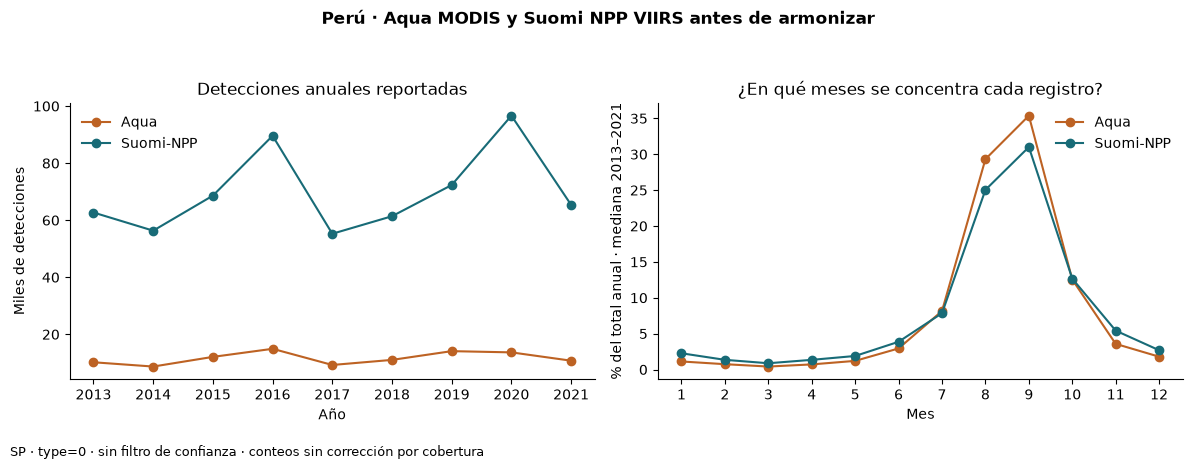

In [5]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
colors = {'Aqua': '#bd6223', 'Suomi-NPP': '#186b77'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for sensor in ['Aqua', 'Suomi-NPP']:
    axes[0].plot(annual.index, annual[sensor] / 1000, 'o-', color=colors[sensor], label=sensor)
    axes[1].plot(season.index, season[sensor], 'o-', color=colors[sensor], label=sensor)
axes[0].set(title='Detecciones anuales reportadas', xlabel='Año', ylabel='Miles de detecciones')
axes[1].set(title='¿En qué meses se concentra cada registro?',
            xlabel='Mes', ylabel='% del total anual · mediana 2013–2021', xticks=range(1, 13))
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
fig.suptitle('Perú · Aqua MODIS y Suomi NPP VIIRS antes de armonizar', fontweight='bold')
fig.text(0.01, 0.01, 'SP · type=0 · sin filtro de confianza · conteos sin corrección por cobertura', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
plt.show()

El panel izquierdo mantiene los conteos originales; el derecho divide cada
mes por el total de ese sensor en ese año y muestra la mediana entre años.
Es posible compartir una temporada de fuego y diferir mucho en cantidad.
La mediana de las proporciones mensuales no tiene por qué sumar exactamente 100 %.

## 3. Sensibilidad a confianza y día/noche
La confianza es un indicador de detección, no una probabilidad comparable
entre instrumentos. Se mide cuánto cambiarían los conteos con el filtro candidato.

In [6]:
confidence = data.groupby('platform').agg(
    detections_all=('platform', 'size'),
    detections_candidate=('candidate_confidence_filter', 'sum'))
confidence['retained_percent'] = confidence.detections_candidate / confidence.detections_all * 100
candidate_annual = (data[data.candidate_confidence_filter]
                    .groupby(['year', 'platform']).size().unstack('platform'))
candidate_annual['ratio_viirs_modis'] = candidate_annual['Suomi-NPP'] / candidate_annual['Aqua']
daynight = data.groupby(['platform', 'daynight']).size().rename('detections').reset_index()
daynight['percent_within_platform'] = daynight.detections / daynight.groupby(
    'platform').detections.transform('sum') * 100
confidence.to_csv(OUT / 'sensibilidad_confianza.csv')
candidate_annual.to_csv(OUT / 'conteos_anuales_confianza_candidata.csv')
daynight.to_csv(OUT / 'distribucion_dia_noche.csv', index=False)
display(confidence.round(2))
display(daynight.round(2))

,detections_all,detections_candidate,retained_percent
platform,,,
Aqua,104675,99415,94.97
Suomi-NPP,628241,593781,94.51


,platform,daynight,detections,percent_within_platform
0,Aqua,D,103328,98.71
1,Aqua,N,1347,1.29
2,Suomi-NPP,D,584943,93.11
3,Suomi-NPP,N,43298,6.89


## 4. ¿Es estable una sola relación VIIRS/MODIS?
Se describen cocientes, no factores de corrección aprobados. Un cociente
nacional reúne fuegos, condiciones de observación y sensibilidades diferentes.

In [7]:
ratio_by_month = monthly.groupby(level='month')['ratio_viirs_modis'].agg(['median', 'min', 'max'])
ratio_by_month.to_csv(OUT / 'cociente_por_mes.csv')
ratios = monthly.ratio_viirs_modis.dropna()
ratio_summary = {
    'monthly_ratio_min': float(ratios.min()),
    'monthly_ratio_q25': float(ratios.quantile(.25)),
    'monthly_ratio_median': float(ratios.median()),
    'monthly_ratio_q75': float(ratios.quantile(.75)),
    'monthly_ratio_max': float(ratios.max()),
    'annual_ratio_min': float(annual.ratio_viirs_modis.min()),
    'annual_ratio_max': float(annual.ratio_viirs_modis.max()),
    'median_monthly_share_peak': {s: int(season[s].idxmax()) for s in colors},
}
display(ratio_by_month.round(2))
display(pd.Series({k: v for k, v in ratio_summary.items() if not isinstance(v, dict)}).to_frame('value').round(3))

,median,min,max
month,,,
1,8.50,7.77,13.72
2,12.18,7.77,17.50
3,12.91,10.58,15.61
4,9.41,6.93,18.07
5,8.45,7.74,10.87
6,7.79,6.67,9.81
7,6.61,5.72,8.33
8,5.16,4.55,10.48
9,4.95,4.33,5.68


,value
monthly_ratio_min,4.326
monthly_ratio_q25,6.606
monthly_ratio_median,8.064
monthly_ratio_q75,10.074
monthly_ratio_max,18.067
annual_ratio_min,5.132
annual_ratio_max,7.073


## 5. Selección inducida por usar solo co-detecciones
Solo se leen las semanas de desarrollo de la malla provisional de 10 km.
Los registros de una plataforma ausente se mantienen NA, no cero.
Las semanas en bordes de bloques se excluyen según la propuesta previa.

In [8]:
weekly = pd.read_csv(SPATIAL / 'conteos_semanales_10km.csv.gz')
weekly = weekly.loc[weekly.split_proposed.eq('development')].copy()
pairs = weekly.pivot(index=['cell_id', 'week_start_utc'], columns='platform', values='n_detections')
both = pairs.notna().all(axis=1)
paired = pairs.loc[both]
national_weekly = weekly.groupby(['week_start_utc', 'platform']).n_detections.sum().unstack('platform')
comparison = pd.DataFrame({
    'all_reported_weekly_counts': pairs.sum(),
    'counts_in_co_detection_units': paired.sum()})
comparison['retained_percent'] = comparison.counts_in_co_detection_units / comparison.all_reported_weekly_counts * 100
comparison.to_csv(OUT / 'sesgo_seleccion_codetecciones.csv')
national_weekly.to_csv(OUT / 'conteos_nacionales_semanales_desarrollo.csv')
assert int(pairs.sum().sum()) == int(weekly.n_detections.sum())
assert pairs.notna().any(axis=1).all()
assert weekly.n_detections.gt(0).all()
pair_diagnostics = {
    'active_cell_weeks': len(pairs), 'both_cell_weeks': int(both.sum()),
    'both_percent': float(both.mean() * 100),
    'aqua_only_cell_weeks': int((pairs.Aqua.notna() & pairs['Suomi-NPP'].isna()).sum()),
    'viirs_only_cell_weeks': int((pairs.Aqua.isna() & pairs['Suomi-NPP'].notna()).sum()),
    'ratio_of_totals_all': float(pairs['Suomi-NPP'].sum() / pairs.Aqua.sum()),
    'ratio_of_totals_codetected': float(paired['Suomi-NPP'].sum() / paired.Aqua.sum()),
}
display(comparison.round(2))
display(pd.Series(pair_diagnostics).to_frame('value').round(3))

,all_reported_weekly_counts,counts_in_co_detection_units,retained_percent
platform,,,
Aqua,104647.0,89475.0,85.50
Suomi-NPP,627731.0,260732.0,41.54


,value
active_cell_weeks,233302.000
both_cell_weeks,45287.000
both_percent,19.411
aqua_only_cell_weeks,12063.000
viirs_only_cell_weeks,175952.000
ratio_of_totals_all,5.999
ratio_of_totals_codetected,2.914


El cociente obtenido usando solo unidades con detecciones de ambas plataformas
puede ser distinto del cociente del registro completo. Ese subconjunto selecciona
actividad más detectable por ambos; no representa todos los casos.

## 6. Días sin detecciones reportadas
Esto detecta huecos en registros positivos. No distingue falta de fuego,
nubes, falta de paso u otra pérdida de datos. No se usa como exposición observada.

In [9]:
calendar = pd.date_range('2013-01-01', '2021-12-31', tz='UTC')
gaps = []
for sensor, group in data.groupby('platform'):
    seen = pd.DatetimeIndex(group.timestamp_utc.dt.normalize().unique())
    no_records = ~calendar.isin(seen)
    longest, running = 0, 0
    for absent in no_records:
        running = running + 1 if absent else 0
        longest = max(longest, running)
    gaps.append({'platform': sensor, 'calendar_days': len(calendar),
                 'days_without_reported_detections': int(no_records.sum()),
                 'longest_streak_no_records_days': longest})
gaps = pd.DataFrame(gaps)
gaps.to_csv(OUT / 'dias_sin_registros.csv', index=False)
display(gaps)

,platform,calendar_days,days_without_reported_detections,longest_streak_no_records_days
0,Aqua,3287,761,6
1,Suomi-NPP,3287,14,1


## 7. Evidencia, estado y próxima decisión humana
En desarrollo: Aqua reportó 104.675 detecciones y Suomi NPP 628.241.
El cociente anual VIIRS/MODIS varió de 5,13 a 7,07. Ambos registros presentan
su mayor concentración mensual mediana en septiembre.
Usar solo co-detecciones conservaría el 85,5 % de los puntos Aqua pero el
41,5 % de los VIIRS en semanas completas: no sería una muestra representativa.
Los filtros candidatos de confianza conservan aproximadamente el 95 % de ambos registros.

No se ha entrenado ningún modelo ni observado métricas de validación/prueba.
Próximo paso propuesto: baseline empírico nacional semanal que exprese VIIRS
en una escala equivalente a Aqua MODIS, conservando observaciones originales.
Hay 468 semanas completas de desarrollo con detecciones nacionales de ambos.
Esto evita restringir el ajuste a las pocas co-detecciones locales, pero no
corrige cobertura desconocida ni valida una calibración local de celdas de 10 km.
La malla se mantiene para exploración y evaluación posterior; una corrección
nacional no debe aplicarse automáticamente a cada celda.
Esa referencia mantiene continuidad histórica; Aqua no se considera verdad de terreno.
Antes de ajustar: aprobar referencia, escala y partición temporal; decidir cómo
tratar cobertura desconocida. Con estos CSV no puede validarse un conteo de incendios
reales ni distinguir ceros verdaderos de observaciones ausentes.
Una sola proporción nacional será solo un baseline, no una corrección universal.

In [10]:
summary = {
    'progress_percent': 65, 'harmonized': False, 'model_fitted': False,
    'analysis_period': '2013-01-01 through 2021-12-31 UTC',
    'heldout_years_used_for_diagnostics': False,
    'grid_km': 10, 'grid_status': 'provisional',
    'development_rows': len(data),
    'source_hashes': source_hashes,
    'ratio_summary': ratio_summary, 'pair_diagnostics': pair_diagnostics,
    'confidence': confidence.reset_index().to_dict(orient='records'),
    'coverage_unknown': True,
    'proposed_reference': 'Aqua-MODIS-equivalent reported detection activity, not true fire counts',
    'proposed_baseline_scope': 'National weekly empirical comparison; not local cell calibration',
    'approval_required_before_model': ['reference_scale', 'grid', 'temporal_split', 'missing_observation_treatment'],
}
(OUT / 'diagnostico.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Diagnóstico completado. Armonización y entrenamiento pendientes de revisión humana.')

Diagnóstico completado. Armonización y entrenamiento pendientes de revisión humana.
